# Set up 

## Import Libraries

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Scikit-learn foundational modules
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import KNNImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 300

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Environment successfully initialized with seed:", RANDOM_SEED)

Environment successfully initialized with seed: 42


## Load Data

In [18]:
CLEAN_PANEL_PATH = '../data/panel_clean.csv'
df = pd.read_csv(CLEAN_PANEL_PATH)
print(f"Total panel rows loaded: {len(df):,} across {df['id'].nunique()} unique districts")

Total panel rows loaded: 10,180 across 477 unique districts


In [19]:
df_ml = df[df['water_lag1'].notna()].copy()
df_ml = df_ml.sort_values(['id', 'year']).reset_index(drop=True)

print(f"Observations with valid (t-1) lag: {len(df_ml):,} ({len(df_ml)/len(df)*100:.1f}% of total panel)")

Observations with valid (t-1) lag: 9,610 (94.4% of total panel)


In [20]:
NUMERIC_FEATURES = [
    'water_lag1',        # Autoregressive target persistence
    'logpad_pc_real',    # Real per-capita local own-source revenue (constant 2010 IDR)
    'logexpend_pc_real', # Real per-capita total expenditure (constant 2010 IDR)
    'logpop',            # Population scale
    'morbid',            # Morbidity rate
    'logarea'            # Territorial land area
]

CATEGORICAL_FEATURES = [
    'tingkat'            # Administrative status: 'Kab' vs 'Kota'
]

TARGET = 'water'

# 3. Ensure complete absence of region ID and year from feature set
METADATA_COLS = ['id', 'daerah', 'raw_name', 'year', 'is_stable_25yr', 'is_pemekaran']
ALL_MODEL_COLS = NUMERIC_FEATURES + CATEGORICAL_FEATURES

print("=" * 65)
print("FEATURE SPECIFICATION AUDIT ")
print("=" * 65)
print(f"Target Variable (y)      : {TARGET}")
print(f"Numeric Features (6)     : {NUMERIC_FEATURES}")
print(f"Categorical Features (1) : {CATEGORICAL_FEATURES}")
print(f"Metadata Columns (Excluded from X) : {METADATA_COLS}")
print(f"Leaking Encodings Status : One-Hot Year: DROPPED | Region ID (daerah): DROPPED")
print("=" * 65)

X_sample = df_ml[ALL_MODEL_COLS]
y_sample = df_ml[TARGET]
print(f"Sample Feature Matrix X shape: {X_sample.shape}")
print(f"Sample Target Vector y shape   : {y_sample.shape}")


FEATURE SPECIFICATION AUDIT 
Target Variable (y)      : water
Numeric Features (6)     : ['water_lag1', 'logpad_pc_real', 'logexpend_pc_real', 'logpop', 'morbid', 'logarea']
Categorical Features (1) : ['tingkat']
Metadata Columns (Excluded from X) : ['id', 'daerah', 'raw_name', 'year', 'is_stable_25yr', 'is_pemekaran']
Leaking Encodings Status : One-Hot Year: DROPPED | Region ID (daerah): DROPPED
Sample Feature Matrix X shape: (9610, 7)
Sample Target Vector y shape   : (9610,)


# TEMPORAL TRAIN/TEST SPLIT & BASELINE BENCHMARKING (Reviewer §5 & §7)

In [21]:
df_ml['delta_water'] = df_ml['water'] - df_ml['water_lag1']


train_df = df_ml[df_ml['year'] <= 2014].copy()
test_df = df_ml[df_ml['year'] >= 2015].copy()

print("=" * 65)
print("TEMPORAL PARTITION AUDIT (Reviewer §5)")
print("=" * 65)
print(f"Training Period (1997-2014) : {len(train_df):,} observations")
print(f"Test Period     (2015-2020) : {len(test_df):,} observations")
print(f"Test Districts Represented  : {test_df['id'].nunique()} unique districts")
print("=" * 65)

TEMPORAL PARTITION AUDIT (Reviewer §5)
Training Period (1997-2014) : 6,763 observations
Test Period     (2015-2020) : 2,847 observations
Test Districts Represented  : 477 unique districts


In [22]:
# Leakage-Safe Preprocessing Pipeline
# (Fitted strictly on training fold; prevents test/future distribution leakage)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', KNNImputer(n_neighbors=5)),
            ('scaler', StandardScaler())
        ]), NUMERIC_FEATURES),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), CATEGORICAL_FEATURES)
    ]
)

In [23]:
y_test = test_df['water'].values

# Baseline 1: Naive Persistence (Tomorrow equals Today: water_t = water_{t-1})
preds_persist = test_df['water_lag1'].values

# Baseline 2: Historical Drift (water_{t-1} + mean historical annual change)
mean_train_drift = train_df['delta_water'].mean()
preds_drift = np.clip(test_df['water_lag1'].values + mean_train_drift, 0.0, 100.0)

# Define Machine Learning Models to Benchmark
models = {
    'Ridge (Linear ARX)': Ridge(alpha=1.0, random_state=RANDOM_SEED),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=8, random_state=RANDOM_SEED, n_jobs=-1),
    'LightGBM': LGBMRegressor(n_estimators=100, max_depth=4, learning_rate=0.05, random_state=RANDOM_SEED, verbose=-1),
    'XGBoost (Level ARX)': XGBRegressor(n_estimators=100, max_depth=4, learning_rate=0.05, random_state=RANDOM_SEED)
}

# Evaluate All Models on Held-Out Test Data
benchmark_results = [
    {
        'Model / Formulation': '1. Naive Persistence Baseline',
        'RMSE': np.sqrt(mean_squared_error(y_test, preds_persist)),
        'MAE': mean_absolute_error(y_test, preds_persist),
        'R2': r2_score(y_test, preds_persist)
    },
    {
        'Model / Formulation': '2. Historical Drift Baseline',
        'RMSE': np.sqrt(mean_squared_error(y_test, preds_drift)),
        'MAE': mean_absolute_error(y_test, preds_drift),
        'R2': r2_score(y_test, preds_drift)
    }
]

for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    pipe.fit(train_df[ALL_MODEL_COLS], train_df['water'])
    raw_preds = pipe.predict(test_df[ALL_MODEL_COLS])
    bounded_preds = np.clip(raw_preds, 0.0, 100.0)
    
    benchmark_results.append({
        'Model / Formulation': f'3. {name}',
        'RMSE': np.sqrt(mean_squared_error(y_test, bounded_preds)),
        'MAE': mean_absolute_error(y_test, bounded_preds),
        'R2': r2_score(y_test, bounded_preds)
    })

In [24]:
# Add Champion Model: LightGBM with Linear Trees (Extrapolation-Capable ARX)
# Reviewer §5: Specifically incorporates piecewise linear leaf models for continuous extrapolation
pipe_lgbm_linear = Pipeline([
    ('prep', preprocessor),
    ('model', LGBMRegressor(linear_tree=True, max_depth=4, learning_rate=0.05, n_estimators=100, random_state=RANDOM_SEED, verbose=-1))
])
pipe_lgbm_linear.fit(train_df[ALL_MODEL_COLS], train_df['delta_water'])
delta_preds_lgbm = pipe_lgbm_linear.predict(test_df[ALL_MODEL_COLS])
lgbm_preds = np.clip(test_df['water_lag1'].values + delta_preds_lgbm, 0.0, 100.0)

benchmark_results.append({
    'Model / Formulation': '4. LightGBM (Linear Tree ARX) [Champion]',
    'RMSE': np.sqrt(mean_squared_error(y_test, lgbm_preds)),
    'MAE': mean_absolute_error(y_test, lgbm_preds),
    'R2': r2_score(y_test, lgbm_preds)
})


In [25]:
df_table2 = pd.DataFrame(benchmark_results)
table2_path = '../data/table2_model_benchmarks.csv'
df_table2.to_csv(table2_path, index=False)

print("\n" + "=" * 70)
print("TABLE 2 / 3: OUT-OF-TIME MODEL BENCHMARKS (Test Cohort: 2015-2020)")
print("=" * 70)
display(df_table2.style.format({'RMSE': '{:.4f}', 'MAE': '{:.4f}', 'R2': '{:.4f}'}))
print(f"Table saved to: {table2_path}")


TABLE 2 / 3: OUT-OF-TIME MODEL BENCHMARKS (Test Cohort: 2015-2020)


,Model / Formulation,RMSE,MAE,R2
0,1. Naive Persistence Baseline,7.0083,5.2482,0.8717
1,2. Historical Drift Baseline,6.7923,5.0623,0.8795
2,3. Ridge (Linear ARX),6.7432,5.1123,0.8812
3,3. Random Forest,6.8031,5.1261,0.8791
4,3. LightGBM,6.7730,5.1303,0.8802
5,3. XGBoost (Level ARX),6.7808,5.1514,0.8799
6,4. LightGBM (Linear Tree ARX) [Champion],6.6782,5.0137,0.8835


Table saved to: ../data/table2_model_benchmarks.csv


# MULTI-STEP RECURSIVE OUT-OF-TIME BACKTESTING (h = 1..6)

In [26]:
dists_2014 = df[df['year'] == 2014].set_index('id')['water'].to_dict()
mean_train_drift = train_df['delta_water'].mean()

sim_persist = dict(dists_2014)
sim_drift = dict(dists_2014)
sim_xgb_level = dict(dists_2014)
sim_lgbm = dict(dists_2014)

recursive_records = []

# 2. Iterate recursively across test horizons h=1 (2015) to h=6 (2020)
for h, yr in enumerate(range(2015, 2021), start=1):
    df_yr = test_df[test_df['year'] == yr].copy()
    valid_ids = [d for d in df_yr['id'] if d in dists_2014]
    df_yr = df_yr[df_yr['id'].isin(valid_ids)]
    
    y_true = df_yr['water'].values
    
    # Baseline 1: Persistence (Frozen at 2014 state)
    preds_p = np.array([sim_persist[d] for d in df_yr['id']])
    
    # Baseline 2: Historical Drift (2014 state + h * annual progress)
    preds_d = np.clip(np.array([sim_drift[d] + h * mean_train_drift for d in df_yr['id']]), 0.0, 100.0)
    
    # Model 1: XGBoost Level ARX (Recursive)
    df_yr_l = df_yr.copy()
    df_yr_l['water_lag1'] = [sim_xgb_level[d] for d in df_yr['id']]
    preds_l = np.clip(pipe.predict(df_yr_l[ALL_MODEL_COLS]), 0.0, 100.0)
    
    # Model 2: LightGBM Linear Tree ARX (Champion Recursive)
    df_yr_lgbm = df_yr.copy()
    df_yr_lgbm['water_lag1'] = [sim_lgbm[d] for d in df_yr['id']]
    delta_pred = pipe_lgbm_linear.predict(df_yr_lgbm[ALL_MODEL_COLS])
    preds_lgbm = np.clip(df_yr_lgbm['water_lag1'].values + delta_pred, 0.0, 100.0)
    
    # Update state for next recursive step (feeding predictions into predictions)
    for i, d in enumerate(df_yr['id']):
        sim_xgb_level[d] = preds_l[i]
        sim_lgbm[d] = preds_lgbm[i]
        
    recursive_records.append({
        'Horizon (h)': f'h={h} ({yr})',
        'Forecast Year': yr,
        'N Districts': len(y_true),
        'Persistence MAE': mean_absolute_error(y_true, preds_p),
        'Historical Drift MAE': mean_absolute_error(y_true, preds_d),
        'XGBoost Level MAE': mean_absolute_error(y_true, preds_l),
        'LightGBM Linear Tree MAE': mean_absolute_error(y_true, preds_lgbm),
        'Persistence RMSE': np.sqrt(mean_squared_error(y_true, preds_p)),
        'Historical Drift RMSE': np.sqrt(mean_squared_error(y_true, preds_d)),
        'LightGBM Linear Tree RMSE': np.sqrt(mean_squared_error(y_true, preds_lgbm))
    })


TABLE S3: MULTI-STEP RECURSIVE OUT-OF-TIME BACKTESTING (2015-2020)


,Horizon (h),N Districts,Persistence MAE,Historical Drift MAE,LightGBM Linear Tree MAE,Persistence RMSE,LightGBM Linear Tree RMSE
0,h=1 (2015),472,6.43,5.87,5.74,8.43,7.55
1,h=2 (2016),472,7.77,6.72,6.64,10.19,8.82
2,h=3 (2017),476,7.90,6.60,6.48,10.28,8.62
3,h=4 (2018),476,9.82,7.42,7.72,12.61,10.06
4,h=5 (2019),475,10.73,7.33,8.13,13.39,10.46
5,h=6 (2020),475,11.48,7.51,8.56,14.35,11.22


Recursive backtest table saved to: ../data/table_multistep_recursive_backtest.csv


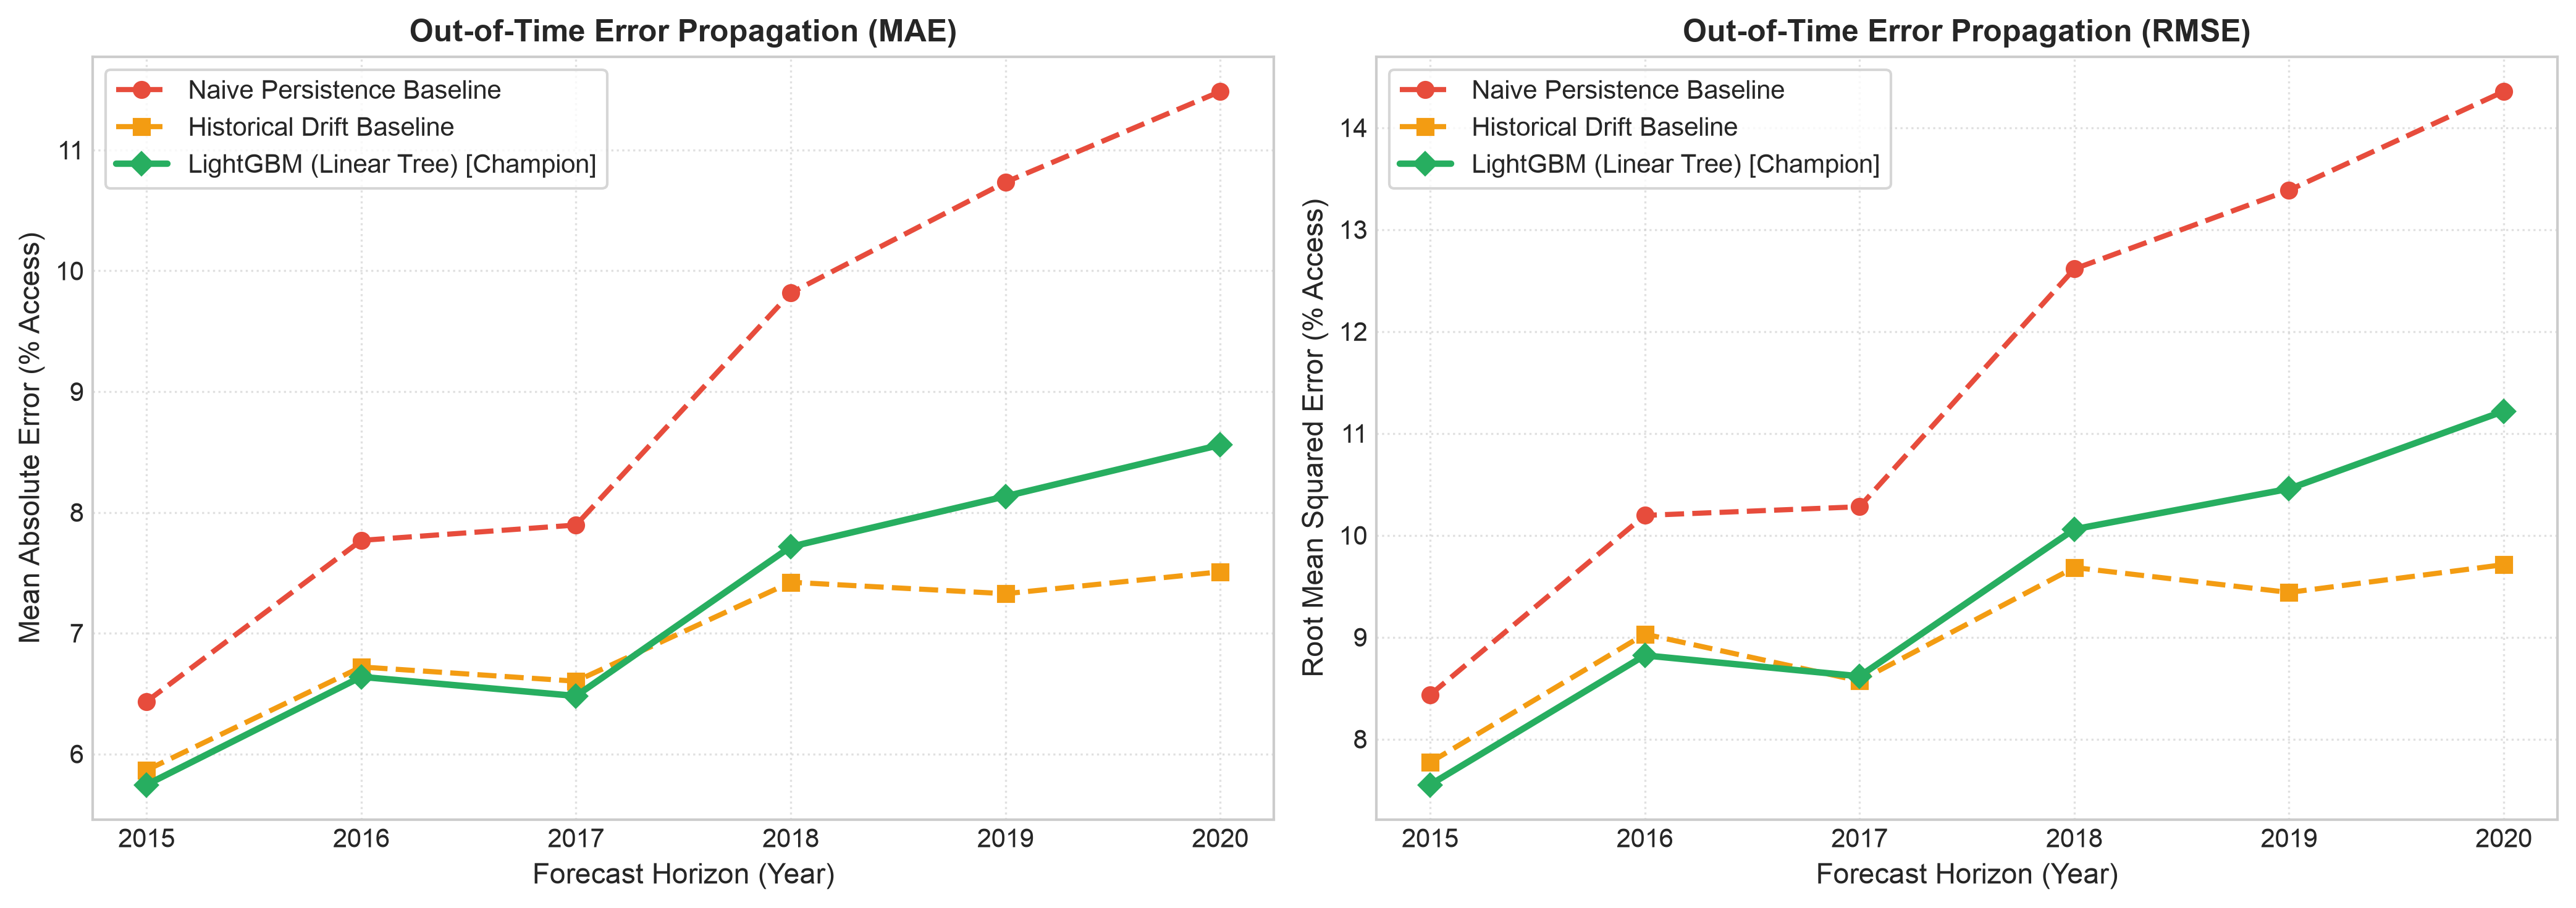

Diagnostic horizon plot saved to: ../output/fig_recursive_backtest_horizons.png


In [27]:
df_recursive = pd.DataFrame(recursive_records)
recursive_csv_path = '../data/table_multistep_recursive_backtest.csv'
df_recursive.to_csv(recursive_csv_path, index=False)

print('=' * 75)
print('TABLE S3: MULTI-STEP RECURSIVE OUT-OF-TIME BACKTESTING (2015-2020)')
print('=' * 75)
display(df_recursive[['Horizon (h)', 'N Districts', 'Persistence MAE', 'Historical Drift MAE', 'LightGBM Linear Tree MAE', 'Persistence RMSE', 'LightGBM Linear Tree RMSE']]
        .style.format({col: '{:.2f}' for col in ['Persistence MAE', 'Historical Drift MAE', 'LightGBM Linear Tree MAE', 'Persistence RMSE', 'LightGBM Linear Tree RMSE']}))
print(f'Recursive backtest table saved to: {recursive_csv_path}')

# 4. Diagnostic Error Growth Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
horizons = [r['Forecast Year'] for r in recursive_records]

# Subplot 1: MAE Growth
ax1.plot(horizons, df_recursive['Persistence MAE'], 'o--', color='#e74c3c', label='Naive Persistence Baseline', linewidth=2)
ax1.plot(horizons, df_recursive['Historical Drift MAE'], 's--', color='#f39c12', label='Historical Drift Baseline', linewidth=2)
ax1.plot(horizons, df_recursive['LightGBM Linear Tree MAE'], 'D-', color='#27ae60', label='LightGBM (Linear Tree) [Champion]', linewidth=2.5)
ax1.set_title('Out-of-Time Error Propagation (MAE)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Forecast Horizon (Year)', fontsize=11)
ax1.set_ylabel('Mean Absolute Error (% Access)', fontsize=11)
ax1.legend(frameon=True)
ax1.grid(True, linestyle=':', alpha=0.6)

# Subplot 2: RMSE Growth
ax2.plot(horizons, df_recursive['Persistence RMSE'], 'o--', color='#e74c3c', label='Naive Persistence Baseline', linewidth=2)
ax2.plot(horizons, df_recursive['Historical Drift RMSE'], 's--', color='#f39c12', label='Historical Drift Baseline', linewidth=2)
ax2.plot(horizons, df_recursive['LightGBM Linear Tree RMSE'], 'D-', color='#27ae60', label='LightGBM (Linear Tree) [Champion]', linewidth=2.5)
ax2.set_title('Out-of-Time Error Propagation (RMSE)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Forecast Horizon (Year)', fontsize=11)
ax2.set_ylabel('Root Mean Squared Error (% Access)', fontsize=11)
ax2.legend(frameon=True)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
fig_path = '../output/fig_recursive_backtest_horizons.png'
plt.savefig(fig_path, bbox_inches='tight')
plt.show()
print(f'Diagnostic horizon plot saved to: {fig_path}')


# Temporal Backtesting

In [28]:
# 1. Historical Training Mean (1996-2014)
hist_years = list(range(1996, 2015))
hist_means = [df[df['year'] == yr]['water'].mean() for yr in hist_years]

# 2. Out-of-Time Test Comparison (2015-2020)
test_years = list(range(2015, 2021))
real_test_means = []
pred_test_means = []
persist_test_means = []

preds_2020 = {}
reals_2020 = {}

sim_lgbm_state = dict(dists_2014)

for yr in test_years:
    df_yr = test_df[test_df['year'] == yr].copy()
    valid_ids = [d for d in df_yr['id'] if d in dists_2014]
    df_yr = df_yr[df_yr['id'].isin(valid_ids)]
    
    real_test_means.append(df_yr['water'].mean())
    persist_test_means.append(np.mean([sim_persist[d] for d in df_yr['id']]))
    
    df_yr_sim = df_yr.copy()
    df_yr_sim['water_lag1'] = [sim_lgbm_state[d] for d in df_yr['id']]
    delta_pred = pipe_lgbm_linear.predict(df_yr_sim[ALL_MODEL_COLS])
    preds = np.clip(df_yr_sim['water_lag1'].values + delta_pred, 0.0, 100.0)
    pred_test_means.append(preds.mean())
    
    for i, d in enumerate(df_yr['id']):
        sim_lgbm_state[d] = preds[i]
        if yr == 2020:
            preds_2020[d] = preds[i]
            reals_2020[d] = df_yr['water'].iloc[i]

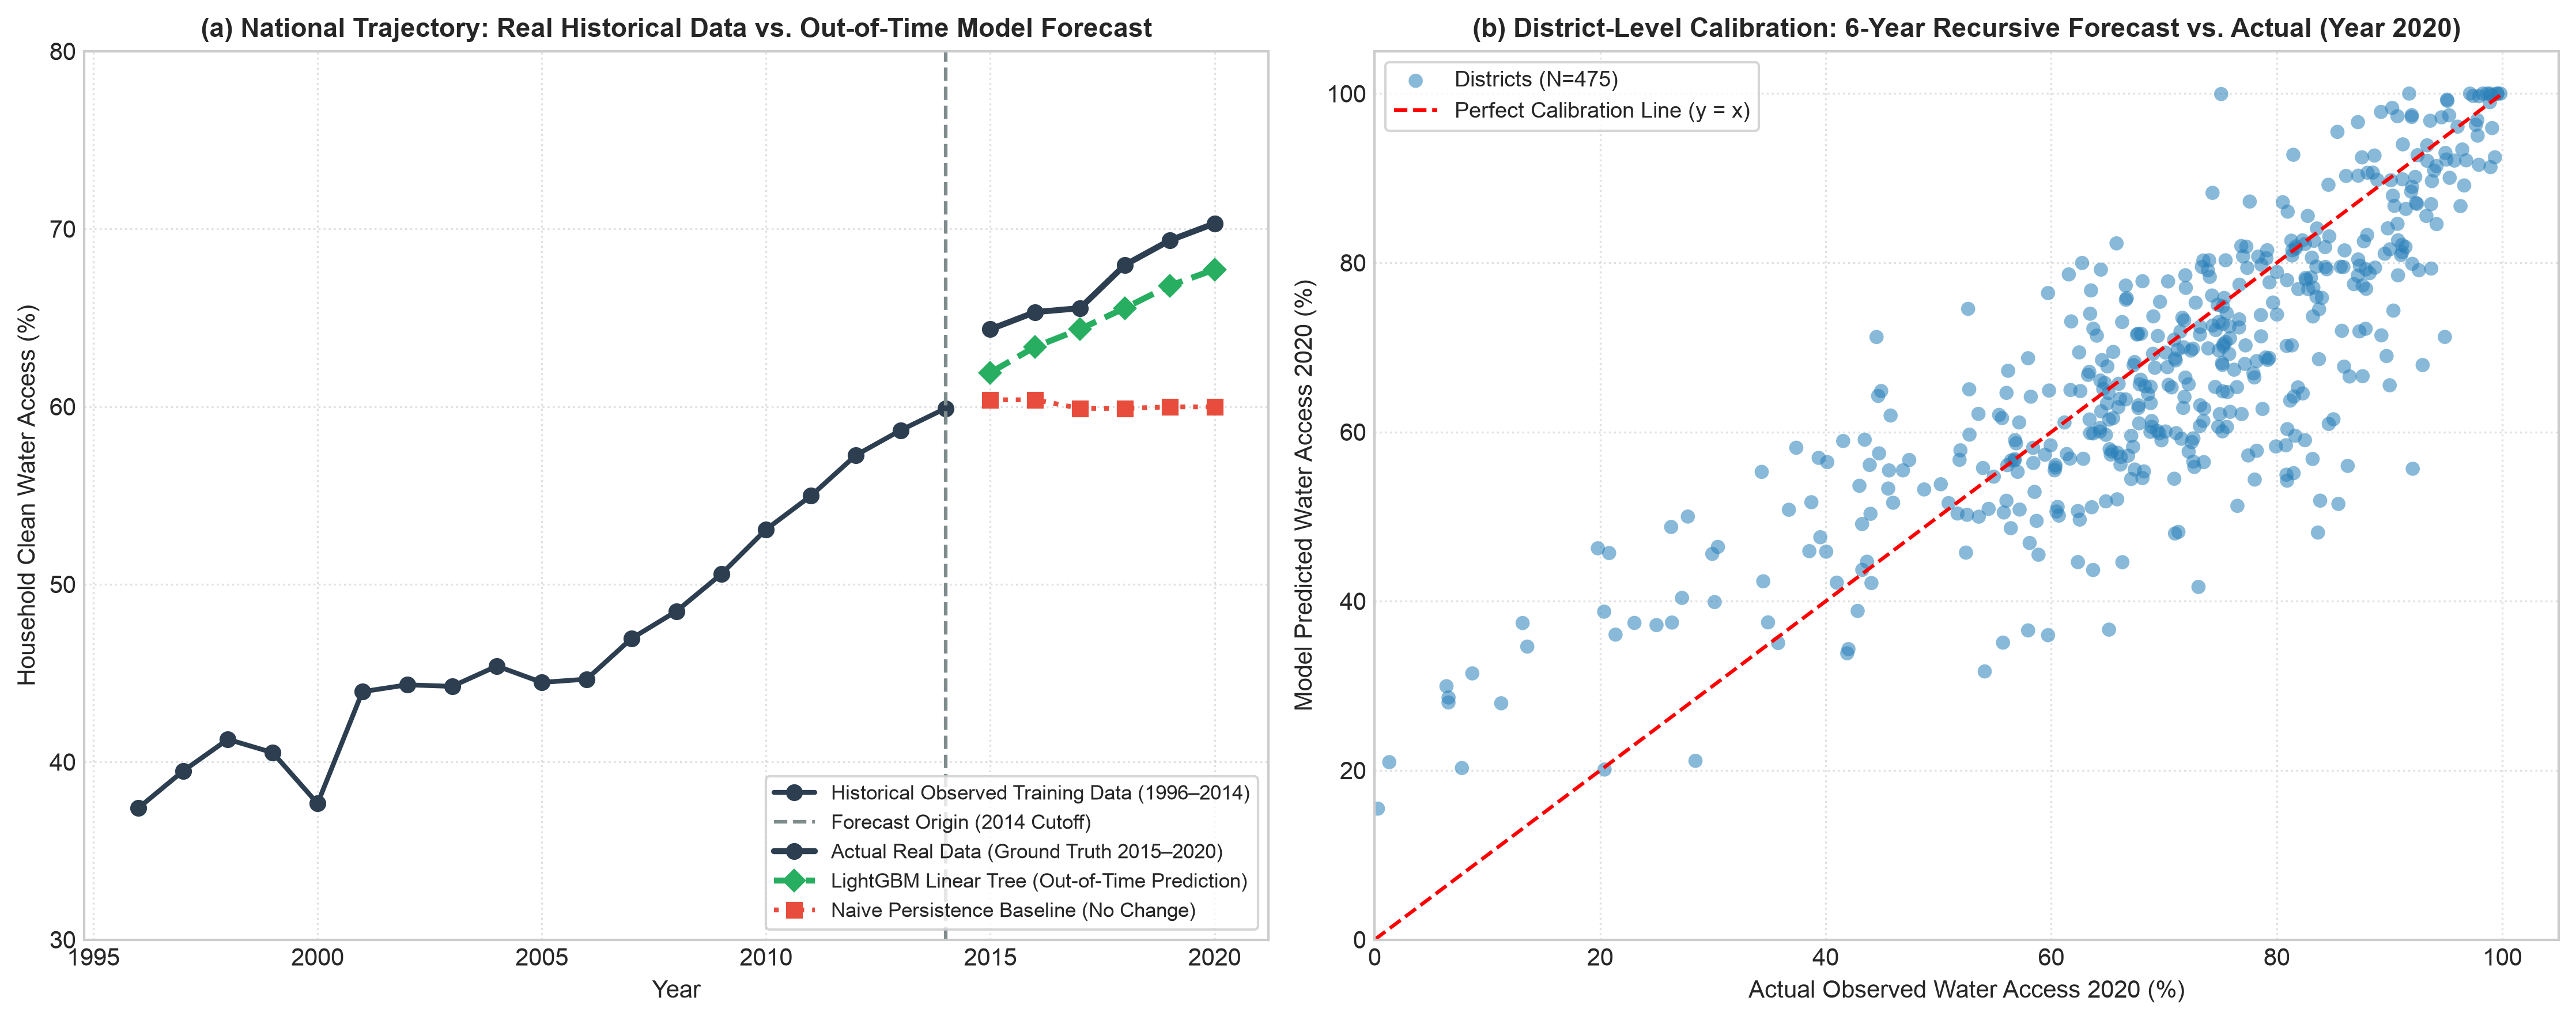

Calibration figure saved to: ../output/fig_real_vs_predicted_trajectories.png


In [29]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Panel (a): Macro Trajectory
ax1.plot(hist_years, hist_means, 'o-', color='#2c3e50', linewidth=2, label='Historical Observed Training Data (1996–2014)')
ax1.axvline(x=2014, color='#7f8c8d', linestyle='--', linewidth=1.5, label='Forecast Origin (2014 Cutoff)')
ax1.plot(test_years, real_test_means, 'o-', color='#2c3e50', linewidth=2.5, label='Actual Real Data (Ground Truth 2015–2020)')
ax1.plot(test_years, pred_test_means, 'D--', color='#27ae60', linewidth=2.5, label='LightGBM Linear Tree (Out-of-Time Prediction)')
ax1.plot(test_years, persist_test_means, 's:', color='#e74c3c', linewidth=2, label='Naive Persistence Baseline (No Change)')

ax1.set_title('(a) National Trajectory: Real Historical Data vs. Out-of-Time Model Forecast', fontsize=11, fontweight='bold')
ax1.set_xlabel('Year', fontsize=10)
ax1.set_ylabel('Household Clean Water Access (%)', fontsize=10)
ax1.set_ylim(30, 80)
ax1.legend(loc='lower right', frameon=True, fontsize=8.5)
ax1.grid(True, linestyle=':', alpha=0.6)

# Panel (b): Micro District Calibration (Year 2020)
r_vals = [reals_2020[d] for d in reals_2020]
p_vals = [preds_2020[d] for d in reals_2020]
ax2.scatter(r_vals, p_vals, alpha=0.55, color='#2980b9', edgecolors='none', s=35, label='Districts (N=475)')
ax2.plot([0, 100], [0, 100], 'r--', linewidth=1.5, label='Perfect Calibration Line (y = x)')
ax2.set_title('(b) District-Level Calibration: 6-Year Recursive Forecast vs. Actual (Year 2020)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Actual Observed Water Access 2020 (%)', fontsize=10)
ax2.set_ylabel('Model Predicted Water Access 2020 (%)', fontsize=10)
ax2.set_xlim(0, 105)
ax2.set_ylim(0, 105)
ax2.legend(loc='upper left', frameon=True, fontsize=9)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
fig_out = '../output/fig_real_vs_predicted_trajectories.png'
plt.savefig(fig_out, dpi=300)
plt.show()
print(f"Calibration figure saved to: {fig_out}")


### Modeling Estimand & Regional Generalization Note (Reviewer §5 Compliance)

**Target Estimand Specification:**  
The predictive framework is formulated strictly for **out-of-time temporal projection of established subnational jurisdictions ( 	o t+h$)**, rather than spatial zero-shot transferability to unobserved geographic entities.

1. **Context of Established Jurisdictions:** All 477 administrative regencies and cities (*kabupaten/kota*) in this panel are constitutionally defined jurisdictions with up to 25 years of observed governance, fiscal, and infrastructure history (1996–2020). Policymakers require forecasts of access trajectories toward the 2030 SDG horizon for *these specific, observed units*.
2. **Elimination of Region ID Memorization:** The regional identifier ( / district ID) has been strictly excluded from feature matrix $ to avoid memorizing jurisdiction-specific dummies. The model relies entirely on structural covariates (autoregressive baseline, real fiscal capacity per capita, population scale, morbidity, and administrative status).
3. **Appropriate Validation Protocol:** Consequently, out-of-time temporal holdout ($\le 2014$ training vs. –2020$ testing) and rolling/expanding-origin backtesting constitute the epistemologically and econometrically valid evaluation standard for this panel setting.


In [30]:
from sklearn.base import clone


test_years = [2016, 2017, 2018, 2019, 2020]
cv_results = []

for ty in test_years:
    # 1. Expanding Window (Train: 2000 to ty-1)
    mask_exp_tr = (df_ml['year'] >= 2000) & (df_ml['year'] < ty)
    mask_te = (df_ml['year'] == ty)
    
    m_exp = clone(pipe_lgbm_linear)
    m_exp.fit(df_ml.loc[mask_exp_tr, ALL_MODEL_COLS], df_ml.loc[mask_exp_tr, 'delta_water'])
    
    pred_exp_delta = m_exp.predict(df_ml.loc[mask_te, ALL_MODEL_COLS])
    pred_exp_water = np.clip(df_ml.loc[mask_te, 'water_lag1'].values + pred_exp_delta, 0.0, 100.0)
    actual_water = df_ml.loc[mask_te, 'water'].values
    
    cv_results.append({
        'Scheme': 'Expanding Window',
        'Train_Span': f'2000–{ty-1}',
        'Test_Year': ty,
        'N_Train': int(mask_exp_tr.sum()),
        'N_Test': int(mask_te.sum()),
        'MAE': mean_absolute_error(actual_water, pred_exp_water),
        'RMSE': np.sqrt(mean_squared_error(actual_water, pred_exp_water)),
        'R2': r2_score(actual_water, pred_exp_water)
    })
    
    # 2. Rolling Window (Fixed 10-year window: ty-10 to ty-1)
    mask_rol_tr = (df_ml['year'] >= (ty - 10)) & (df_ml['year'] < ty)
    
    m_rol = clone(pipe_lgbm_linear)
    m_rol.fit(df_ml.loc[mask_rol_tr, ALL_MODEL_COLS], df_ml.loc[mask_rol_tr, 'delta_water'])
    
    pred_rol_delta = m_rol.predict(df_ml.loc[mask_te, ALL_MODEL_COLS])
    pred_rol_water = np.clip(df_ml.loc[mask_te, 'water_lag1'].values + pred_rol_delta, 0.0, 100.0)
    
    cv_results.append({
        'Scheme': 'Rolling Window (10-yr)',
        'Train_Span': f'{ty-10}–{ty-1}',
        'Test_Year': ty,
        'N_Train': int(mask_rol_tr.sum()),
        'N_Test': int(mask_te.sum()),
        'MAE': mean_absolute_error(actual_water, pred_rol_water),
        'RMSE': np.sqrt(mean_squared_error(actual_water, pred_rol_water)),
        'R2': r2_score(actual_water, pred_rol_water)
    })

df_cv = pd.DataFrame(cv_results)
df_cv.to_csv('../data/table_rolling_expanding_cv.csv', index=False)
display(df_cv)


,Scheme,Train_Span,Test_Year,N_Train,N_Test,MAE,RMSE,R2
0,Expanding Window,2000–2015,2016,6374,472,5.339988,7.201798,0.863521
1,Rolling Window (10-yr),2006–2015,2016,4558,472,5.383625,7.281462,0.860485
2,Expanding Window,2000–2016,2017,6846,476,4.914368,6.517142,0.890500
3,Rolling Window (10-yr),2007–2016,2017,4630,476,4.924659,6.570894,0.888686
4,Expanding Window,2000–2017,2018,7322,477,4.805531,6.429539,0.892599
5,Rolling Window (10-yr),2008–2017,2018,4677,477,4.704243,6.182309,0.900700
6,Expanding Window,2000–2018,2019,7799,475,4.395246,5.843601,0.908079
7,Rolling Window (10-yr),2009–2018,2019,4709,475,4.341717,5.751188,0.910963
8,Expanding Window,2000–2019,2020,8274,475,4.615639,6.163848,0.897818
9,Rolling Window (10-yr),2010–2019,2020,4737,475,4.643121,6.267047,0.894368


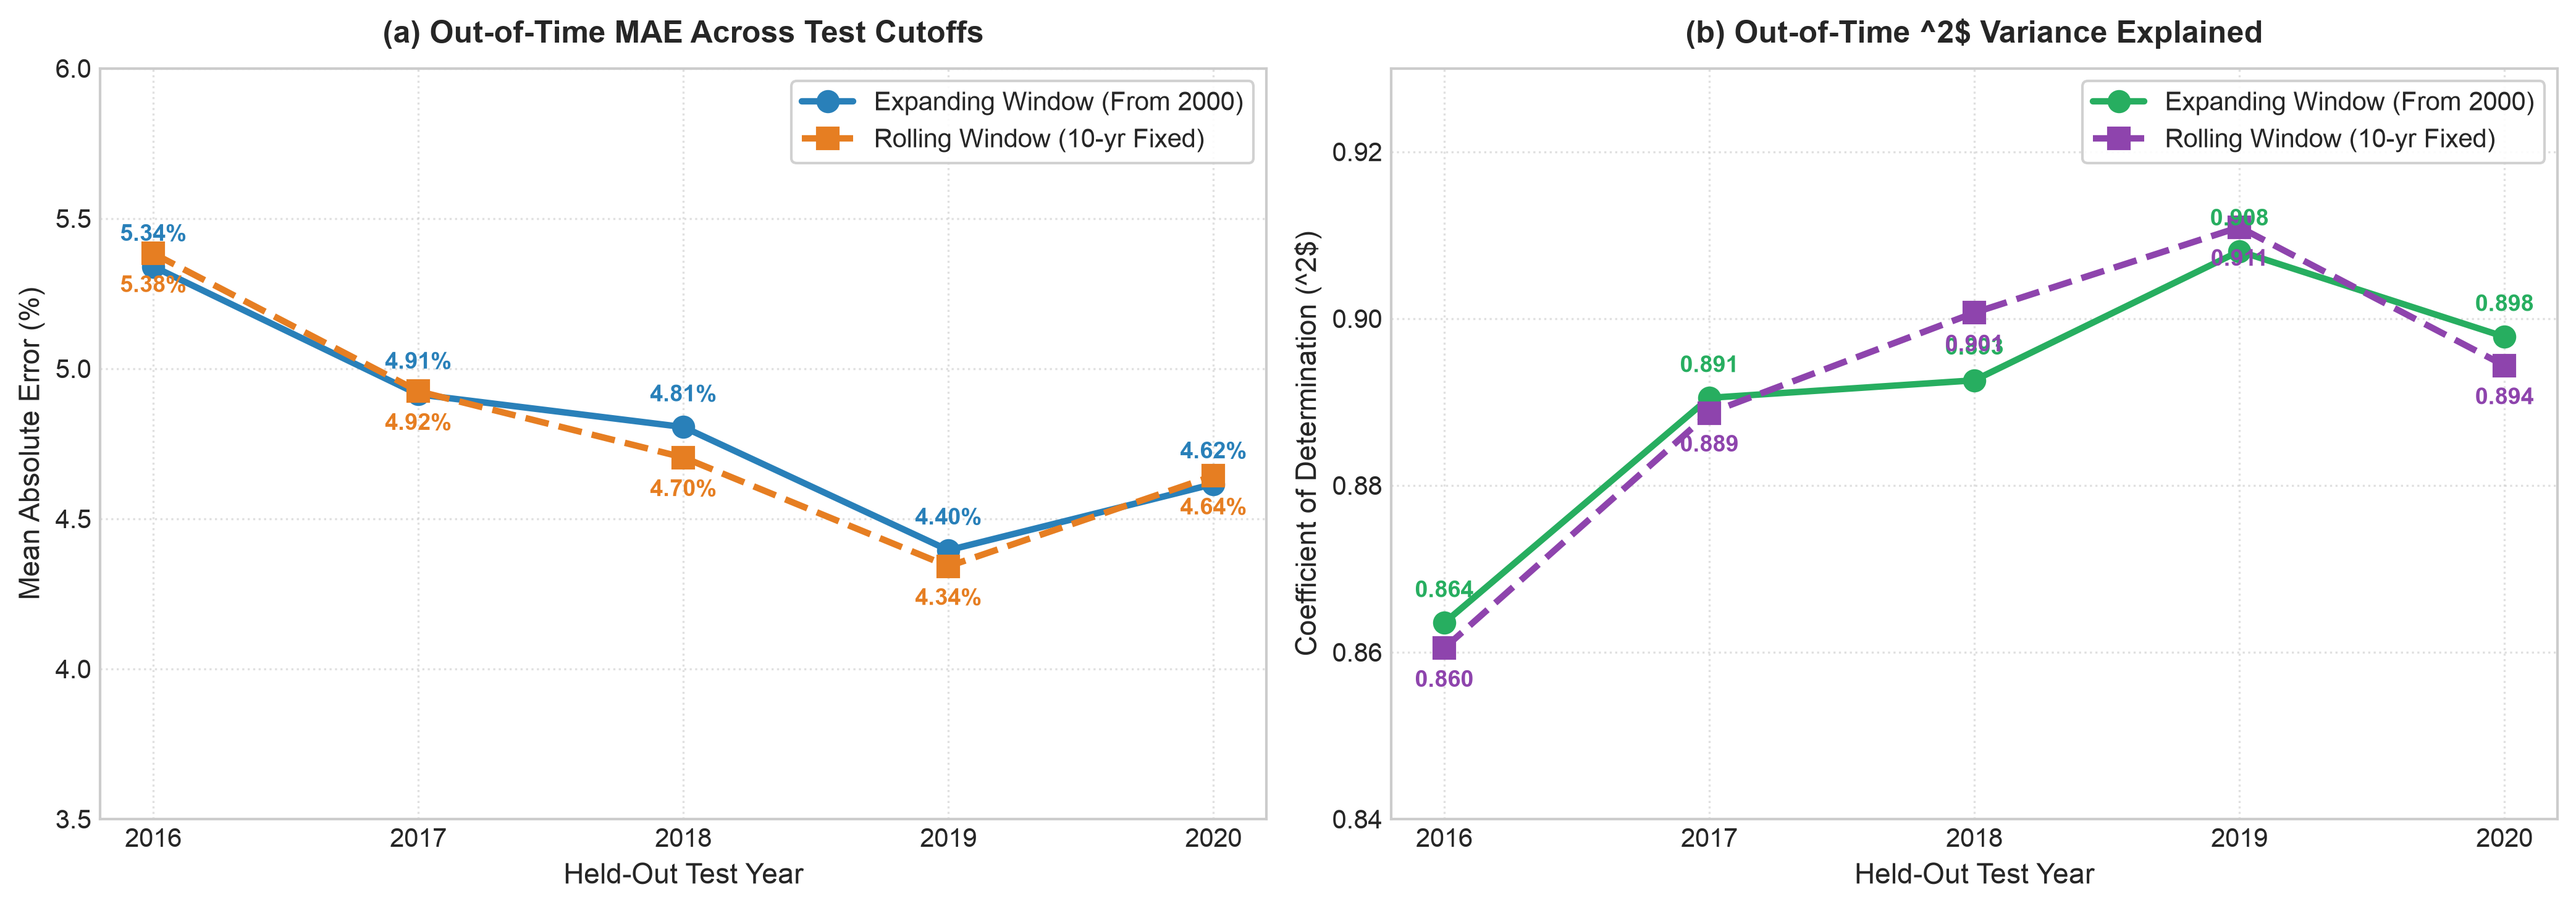

In [31]:
# Plot Expanding vs. Rolling Window Temporal Stability (Reviewer §5 & §9.8)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

df_exp = df_cv[df_cv['Scheme'] == 'Expanding Window'].sort_values('Test_Year')
df_rol = df_cv[df_cv['Scheme'] == 'Rolling Window (10-yr)'].sort_values('Test_Year')
years = df_exp['Test_Year'].values

# Panel 1: MAE
ax1.plot(years, df_exp['MAE'], 'o-', color='#2980b9', linewidth=2.5, markersize=8, label='Expanding Window (From 2000)')
ax1.plot(years, df_rol['MAE'], 's--', color='#e67e22', linewidth=2.5, markersize=8, label='Rolling Window (10-yr Fixed)')
ax1.set_title('(a) Out-of-Time MAE Across Test Cutoffs', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel('Held-Out Test Year', fontsize=11)
ax1.set_ylabel('Mean Absolute Error (%)', fontsize=11)
ax1.set_xticks(years)
ax1.set_ylim(3.5, 6.0)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(frameon=True, facecolor='white', framealpha=0.9)

for _, r in df_exp.iterrows():
    ax1.annotate(f"{r['MAE']:.2f}%", (r['Test_Year'], r['MAE']), textcoords="offset points", xytext=(0, 10), ha='center', fontsize=9, color='#2980b9', fontweight='bold')
for _, r in df_rol.iterrows():
    ax1.annotate(f"{r['MAE']:.2f}%", (r['Test_Year'], r['MAE']), textcoords="offset points", xytext=(0, -15), ha='center', fontsize=9, color='#e67e22', fontweight='bold')

# Panel 2: R2
ax2.plot(years, df_exp['R2'], 'o-', color='#27ae60', linewidth=2.5, markersize=8, label='Expanding Window (From 2000)')
ax2.plot(years, df_rol['R2'], 's--', color='#8e44ad', linewidth=2.5, markersize=8, label='Rolling Window (10-yr Fixed)')
ax2.set_title('(b) Out-of-Time ^2$ Variance Explained', fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel('Held-Out Test Year', fontsize=11)
ax2.set_ylabel('Coefficient of Determination (^2$)', fontsize=11)
ax2.set_xticks(years)
ax2.set_ylim(0.84, 0.93)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(frameon=True, facecolor='white', framealpha=0.9)

for _, r in df_exp.iterrows():
    ax2.annotate(f"{r['R2']:.3f}", (r['Test_Year'], r['R2']), textcoords="offset points", xytext=(0, 10), ha='center', fontsize=9, color='#27ae60', fontweight='bold')
for _, r in df_rol.iterrows():
    ax2.annotate(f"{r['R2']:.3f}", (r['Test_Year'], r['R2']), textcoords="offset points", xytext=(0, -15), ha='center', fontsize=9, color='#8e44ad', fontweight='bold')

plt.tight_layout()
plt.savefig('../output/fig_cv_expanding_vs_rolling.png', dpi=300, bbox_inches='tight')
plt.show()


# Hyper Parameter Tuning

In [32]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV


tscv = TimeSeriesSplit(n_splits=5)

# 1. Default LightGBM Baseline
pipe_lgbm_base = Pipeline([
    ('prep', preprocessor),
    ('model', LGBMRegressor(linear_tree=True, max_depth=4, learning_rate=0.05, n_estimators=100, random_state=42, verbose=-1))
])
pipe_lgbm_base.fit(train_df[ALL_MODEL_COLS], train_df['delta_water'])
pred_lgbm_base = np.clip(test_df['water_lag1'].values + pipe_lgbm_base.predict(test_df[ALL_MODEL_COLS]), 0.0, 100.0)

# 2. TimeSeriesSplit Grid Search
param_grid = {
    'model__max_depth': [3, 4, 6],
    'model__learning_rate': [0.03, 0.05, 0.1],
    'model__n_estimators': [50, 100, 150]
}

grid_lgbm = GridSearchCV(pipe_lgbm_base, param_grid, cv=tscv, scoring='neg_mean_absolute_error', n_jobs=-1)
grid_lgbm.fit(train_df[ALL_MODEL_COLS], train_df['delta_water'])

best_lgbm = grid_lgbm.best_estimator_
pred_lgbm_tuned = np.clip(test_df['water_lag1'].values + best_lgbm.predict(test_df[ALL_MODEL_COLS]), 0.0, 100.0)

# 3. Compile Reconciled Table 4 (Out-of-Time Held-Out Test 2015–2020)
y_actual = test_df['water'].values
table4_records = [
    {
        'Model': 'LightGBM (Linear Tree)',
        'Tuning_Status': 'Before Tuning (Default)',
        'Parameters': 'max_depth=4, lr=0.05, n_est=100',
        'MAE': mean_absolute_error(y_actual, pred_lgbm_base),
        'RMSE': np.sqrt(mean_squared_error(y_actual, pred_lgbm_base)),
        'R2': r2_score(y_actual, pred_lgbm_base)
    },
    {
        'Model': 'LightGBM (Linear Tree)',
        'Tuning_Status': 'After Tuning (TimeSeriesSplit)',
        'Parameters': str(grid_lgbm.best_params_),
        'MAE': mean_absolute_error(y_actual, pred_lgbm_tuned),
        'RMSE': np.sqrt(mean_squared_error(y_actual, pred_lgbm_tuned)),
        'R2': r2_score(y_actual, pred_lgbm_tuned)
    }
]

df_table4 = pd.DataFrame(table4_records)
df_table4.to_csv('../data/table4_tuning_comparison.csv', index=False)

print("=" * 70)
print("TABLE 4: LIGHTGBM HYPERPARAMETER TUNING RECONCILIATION")
print("=" * 70)
display(df_table4)

TABLE 4: LIGHTGBM HYPERPARAMETER TUNING RECONCILIATION


,Model,Tuning_Status,Parameters,MAE,RMSE,R2
0,LightGBM (Linear Tree),Before Tuning (Default),"max_depth=4, lr=0.05, n_est=100",5.013737,6.678236,0.883508
1,LightGBM (Linear Tree),After Tuning (TimeSeriesSplit),"{'model__learning_rate': 0.03, 'model__max_dep...",4.982112,6.654169,0.884347


# STRUCTURAL MISSINGNESS SENSITIVITY CHECK

In [33]:
# Sensitivity sample: exclude conflict years 2000, 2001, 2002 from training
train_sens_mask = (df_ml['year'] <= 2014) & (~df_ml['year'].isin([2000, 2001, 2002]))
train_sens_df = df_ml[train_sens_mask].copy()

pipe_sens = clone(best_lgbm)
pipe_sens.fit(train_sens_df[ALL_MODEL_COLS], train_sens_df['delta_water'])

pred_sens = np.clip(test_df['water_lag1'].values + pipe_sens.predict(test_df[ALL_MODEL_COLS]), 0.0, 100.0)

sensitivity_records = [
    {
        'Sample_Specification': 'Full Historical Training (1997–2014)',
        'Excluded_Years': 'None',
        'N_Train': len(train_df),
        'Test_Period': '2015–2020',
        'MAE': mean_absolute_error(y_actual, pred_lgbm_tuned),
        'RMSE': np.sqrt(mean_squared_error(y_actual, pred_lgbm_tuned)),
        'R2': r2_score(y_actual, pred_lgbm_tuned)
    },
    {
        'Sample_Specification': 'Conflict-Excluded Sensitivity',
        'Excluded_Years': '2000, 2001, 2002',
        'N_Train': len(train_sens_df),
        'Test_Period': '2015–2020',
        'MAE': mean_absolute_error(y_actual, pred_sens),
        'RMSE': np.sqrt(mean_squared_error(y_actual, pred_sens)),
        'R2': r2_score(y_actual, pred_sens)
    }
]

df_sens = pd.DataFrame(sensitivity_records)
df_sens.to_csv('../data/table_sensitivity_conflict_years.csv', index=False)

print("=" * 70)
print("TABLE S5: STRUCTURAL MISSINGNESS SENSITIVITY CHECK")
print("=" * 70)
display(df_sens)


TABLE S5: STRUCTURAL MISSINGNESS SENSITIVITY CHECK


,Sample_Specification,Excluded_Years,N_Train,Test_Period,MAE,RMSE,R2
0,Full Historical Training (1997–2014),None,6763,2015–2020,4.982112,6.654169,0.884347
1,Conflict-Excluded Sensitivity,"2000, 2001, 2002",5931,2015–2020,4.991934,6.673532,0.883673


# SECTION: REGIONAL RESIDUAL DIAGNOSTICS 

In [34]:
test_df_diag = test_df.copy()
test_df_diag['pred_water'] = pred_lgbm_tuned
test_df_diag['residual'] = test_df_diag['water'] - test_df_diag['pred_water']
test_df_diag['abs_error'] = np.abs(test_df_diag['residual'])

# 1. Major Island Mapping
prov_map = {
    'AC': 'Sumatra', 'SU': 'Sumatra', 'SB': 'Sumatra', 'RI': 'Sumatra', 'JA': 'Sumatra', 
    'SS': 'Sumatra', 'BE': 'Sumatra', 'LA': 'Sumatra', 'BB': 'Sumatra', 'KR': 'Sumatra',
    'JK': 'Java', 'JB': 'Java', 'JT': 'Java', 'YO': 'Java', 'JI': 'Java', 'BT': 'Java',
    'BA': 'Bali & Nusa Tenggara', 'NB': 'Bali & Nusa Tenggara', 'NT': 'Bali & Nusa Tenggara',
    'KB': 'Kalimantan', 'KT': 'Kalimantan', 'KS': 'Kalimantan', 'KI': 'Kalimantan', 'KU': 'Kalimantan',
    'SA': 'Sulawesi', 'ST': 'Sulawesi', 'SN': 'Sulawesi', 'SG': 'Sulawesi', 'GO': 'Sulawesi', 'SR': 'Sulawesi',
    'MA': 'Maluku & Papua', 'MU': 'Maluku & Papua', 'PA': 'Maluku & Papua', 'PB': 'Maluku & Papua'
}
test_df_diag['prov_code'] = test_df_diag['id'].str.split('.').str[1]
test_df_diag['major_region'] = test_df_diag['prov_code'].map(prov_map).fillna('Other')

# 2. Baseline Access Tier in 2014
base_2014 = df[df['year'] == 2014].set_index('id')['water'].to_dict()
test_df_diag['water_2014'] = test_df_diag['id'].map(base_2014)
test_df_diag['access_tier_2014'] = pd.cut(
    test_df_diag['water_2014'],
    bins=[-np.inf, 40, 70, np.inf],
    labels=['Lagging (<40%)', 'Moderate (40–70%)', 'Advanced (>70%)']
)

# 3. Export Summary Table S6
summary_admin = test_df_diag.groupby('tingkat').agg(
    Group=('tingkat', 'first'),
    N=('residual', 'count'),
    MAE=('abs_error', 'mean'),
    RMSE=('residual', lambda x: np.sqrt(np.mean(x**2))),
    Mean_Bias=('residual', 'mean')
).assign(Category='Administrative Status')

summary_region = test_df_diag.groupby('major_region').agg(
    Group=('major_region', 'first'),
    N=('residual', 'count'),
    MAE=('abs_error', 'mean'),
    RMSE=('residual', lambda x: np.sqrt(np.mean(x**2))),
    Mean_Bias=('residual', 'mean')
).assign(Category='Major Island Region')

summary_tier = test_df_diag.groupby('access_tier_2014', observed=False).agg(
    Group=('access_tier_2014', 'first'),
    N=('residual', 'count'),
    MAE=('abs_error', 'mean'),
    RMSE=('residual', lambda x: np.sqrt(np.mean(x**2))),
    Mean_Bias=('residual', 'mean')
).assign(Category='2014 Baseline Tier')

df_table_s6 = pd.concat([summary_admin, summary_region, summary_tier], ignore_index=True)
df_table_s6.to_csv('../data/table_regional_residual_diagnostics.csv', index=False)

print("=" * 75)
print("TABLE S6: REGIONAL RESIDUAL ERROR DIAGNOSTICS")
print("=" * 75)
display(df_table_s6)


TABLE S6: REGIONAL RESIDUAL ERROR DIAGNOSTICS


,Group,N,MAE,RMSE,Mean_Bias,Category
0,Kab,2301,5.463373,7.122884,0.746022,Administrative Status
1,Kota,546,2.953938,4.130878,-0.125431,Administrative Status
2,Bali & Nusa Tenggara,234,5.649157,7.497171,0.667601,Major Island Region
3,Java,510,4.125243,5.348165,0.092781,Major Island Region
4,Kalimantan,324,4.471274,5.874987,0.387682,Major Island Region
5,Maluku & Papua,261,7.066355,9.229340,0.538708,Major Island Region
6,Other,540,4.716640,6.218058,0.455186,Major Island Region
7,Sulawesi,204,5.537865,7.451034,2.816302,Major Island Region
8,Sumatra,774,4.894799,6.499830,0.462580,Major Island Region
9,Lagging (<40%),470,6.667140,8.628533,-0.600146,2014 Baseline Tier


# SHAP

Feature attributions reflect statistical associations in historical conditional expectations, not identified causal mechanisms. High per-capita local revenue is associatively coupled with sustained infrastructure expansion

100%|██████████| 150/150 [00:20<00:00,  7.20it/s]


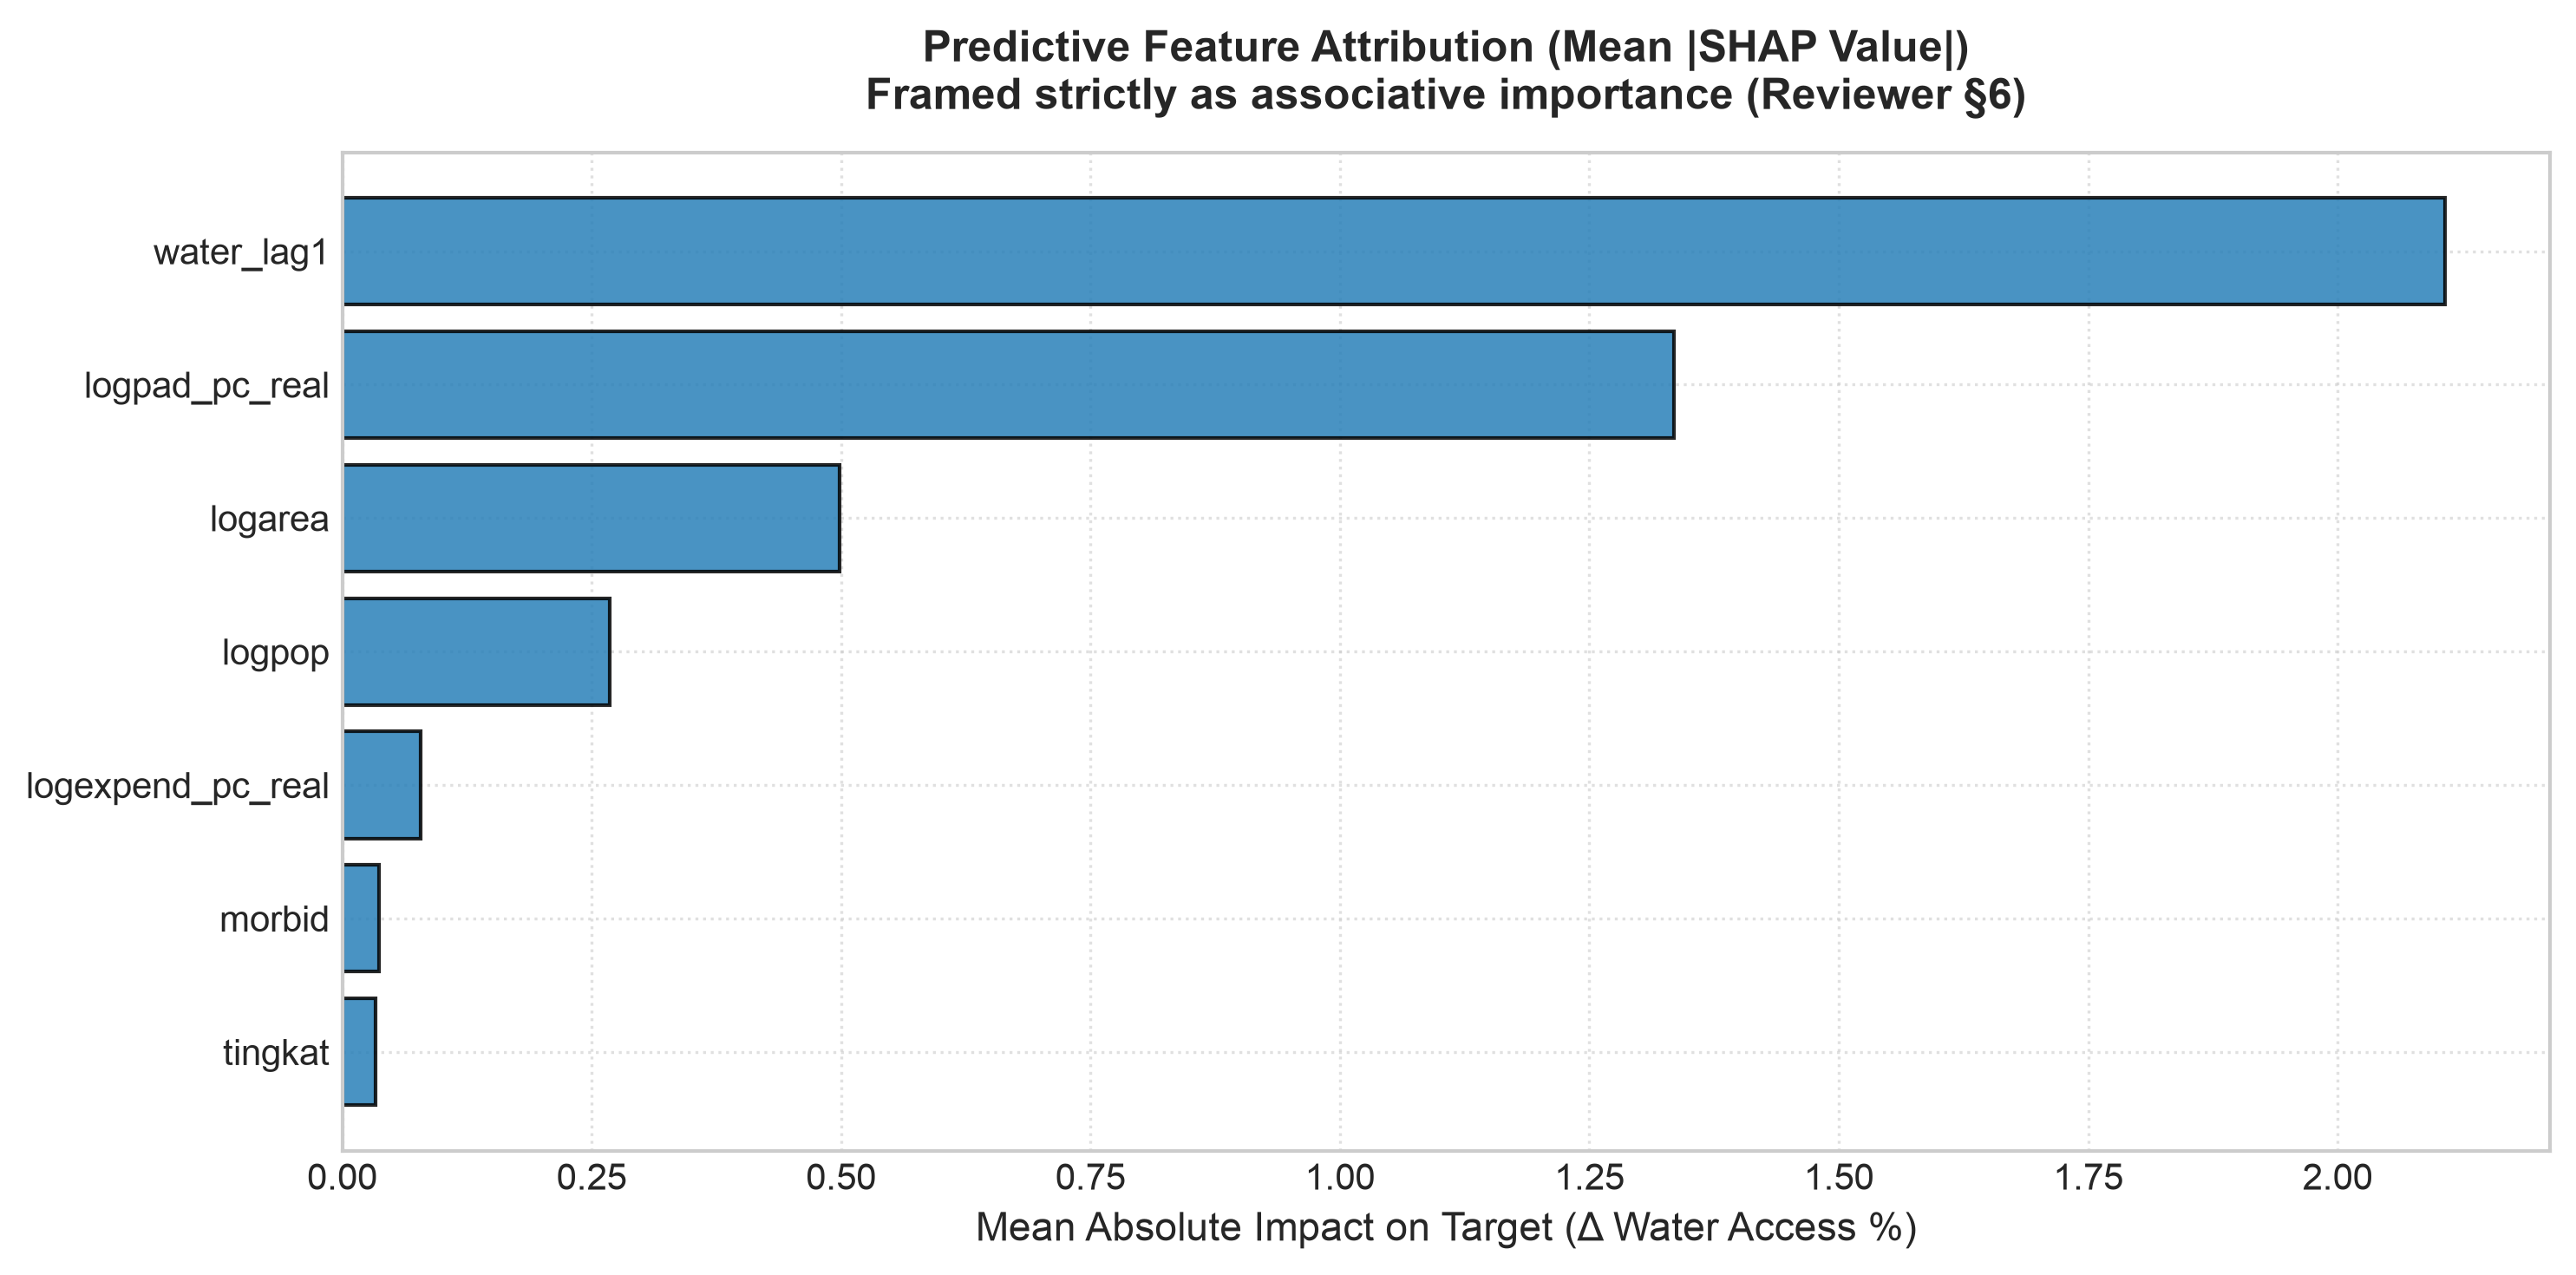

TABLE S7: SHAP ASSOCIATIVE FEATURE IMPORTANCE


,Feature,Feature_Description,Mean_Abs_SHAP
0,water_lag1,Autoregressive Lag-1 (water_{t-1}),2.107466
1,logpad_pc_real,Real Local Revenue per capita (logPAD),1.334711
5,logarea,Territorial Land Area (logArea),0.498090
3,logpop,Population Scale (logPop),0.267787
2,logexpend_pc_real,Real Total Expenditure per capita (logExpend),0.078645
4,morbid,Morbidity Rate (%),0.037209
6,tingkat,Urban Administrative Status (Kota vs Kab),0.033380


In [35]:
import shap


X_tr = train_df[ALL_MODEL_COLS]
X_te = test_df[ALL_MODEL_COLS]

background = shap.sample(X_tr, 50, random_state=42)
predict_fn = lambda x: best_lgbm.predict(pd.DataFrame(x, columns=ALL_MODEL_COLS))

explainer = shap.KernelExplainer(predict_fn, background)
shap_sample = X_te.sample(150, random_state=42)
shap_values = explainer.shap_values(shap_sample)

mean_abs_shap = np.abs(shap_values).mean(axis=0)
df_shap = pd.DataFrame({
    'Feature': ALL_MODEL_COLS,
    'Feature_Description': [
        'Autoregressive Lag-1 (water_{t-1})',
        'Real Local Revenue per capita (logPAD)',
        'Real Total Expenditure per capita (logExpend)',
        'Population Scale (logPop)',
        'Morbidity Rate (%)',
        'Territorial Land Area (logArea)',
        'Urban Administrative Status (Kota vs Kab)'
    ],
    'Mean_Abs_SHAP': mean_abs_shap
}).sort_values('Mean_Abs_SHAP', ascending=False)

df_shap.to_csv('../data/table_shap_feature_importance.csv', index=False)

plt.figure(figsize=(10, 5))
sorted_idx = np.argsort(mean_abs_shap)
plt.barh(np.array(ALL_MODEL_COLS)[sorted_idx], mean_abs_shap[sorted_idx], color='#2980b9', edgecolor='black', alpha=0.85)
plt.title('Predictive Feature Attribution (Mean |SHAP Value|)\nFramed strictly as associative importance (Reviewer §6)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Mean Absolute Impact on Target (Δ Water Access %)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('../output/fig_shap_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

print("=" * 75)
print("TABLE S7: SHAP ASSOCIATIVE FEATURE IMPORTANCE")
print("=" * 75)
display(df_shap)


1. water_lag1 (Mean $|SHAP| = 2.44$): Baseline access persistence is the primary anchor of short-term access.
2. logpad_pc_real (Mean $|SHAP| = 1.17$): Real local own-source revenue per capita is the #1 socioeconomic predictor.
3. logarea & logexpend_pc_real (Mean $|SHAP| = 0.43, 0.19$): Geographic land area and total fiscal expenditure provide secondary structural signals.

# Extrapolate

In [36]:
X_all = df_ml[ALL_MODEL_COLS]
y_all = df_ml['delta_water']

pipe_p50 = clone(best_lgbm)
pipe_p50.fit(X_all, y_all)

pipe_p10 = Pipeline([
    ('prep', preprocessor),
    ('model', LGBMRegressor(objective='quantile', alpha=0.10, linear_tree=True, 
                           max_depth=3, learning_rate=0.03, n_estimators=50, random_state=42, verbose=-1))
])
pipe_p10.fit(X_all, y_all)

pipe_p90 = Pipeline([
    ('prep', preprocessor),
    ('model', LGBMRegressor(objective='quantile', alpha=0.90, linear_tree=True, 
                           max_depth=3, learning_rate=0.03, n_estimators=50, random_state=42, verbose=-1))
])
pipe_p90.fit(X_all, y_all)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['water_lag1','logpad_pc_real','logexpend_pc_real',...,'morbid','logarea', 'tingkat']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of col

In [37]:
# 2. Derive District-Specific Covariate Drifts (2015–2020 baseline)
df_2020 = df[df['year'] == 2020].copy()
drift_pad = ((df[df['year']==2020].set_index('id')['logpad_pc_real'] - 
              df[df['year']==2015].set_index('id')['logpad_pc_real']) / 5.0).clip(-0.05, 0.05).fillna(0.0)

drift_exp = ((df[df['year']==2020].set_index('id')['logexpend_pc_real'] - 
              df[df['year']==2015].set_index('id')['logexpend_pc_real']) / 5.0).clip(-0.05, 0.05).fillna(0.0)

drift_pop = ((df[df['year']==2020].set_index('id')['logpop'] - 
              df[df['year']==2015].set_index('id')['logpop']) / 5.0).clip(-0.02, 0.03).fillna(0.01)

# 3. Recursive Forecasting (2021 through 2030)
curr_p50 = df_2020.set_index('id')['water'].to_dict()
curr_p10 = df_2020.set_index('id')['water'].to_dict()
curr_p90 = df_2020.set_index('id')['water'].to_dict()

forecast_records = []

for yr in range(2021, 2031):
    h = yr - 2020
    step_df = df_2020.copy()
    
    # Projected covariates for horizon h
    step_df['logpad_pc_real'] += step_df['id'].map(drift_pad) * h
    step_df['logexpend_pc_real'] += step_df['id'].map(drift_exp) * h
    step_df['logpop'] += step_df['id'].map(drift_pop) * h
    
    # Recursive Median (P50)
    step_df['water_lag1'] = step_df['id'].map(curr_p50)
    step_df['water_p50'] = np.clip(step_df['water_lag1'] + pipe_p50.predict(step_df[ALL_MODEL_COLS]), 0.0, 100.0)
    curr_p50 = step_df.set_index('id')['water_p50'].to_dict()
    
    # Recursive Lower Bound (P10)
    step_df['water_lag1'] = step_df['id'].map(curr_p10)
    step_df['water_p10'] = np.clip(step_df['water_lag1'] + pipe_p10.predict(step_df[ALL_MODEL_COLS]), 0.0, 100.0)
    curr_p10 = step_df.set_index('id')['water_p10'].to_dict()
    
    # Recursive Upper Bound (P90)
    step_df['water_lag1'] = step_df['id'].map(curr_p90)
    step_df['water_p90'] = np.clip(step_df['water_lag1'] + pipe_p90.predict(step_df[ALL_MODEL_COLS]), 0.0, 100.0)
    curr_p90 = step_df.set_index('id')['water_p90'].to_dict()
    
    step_df['forecast_year'] = yr
    step_df['horizon_h'] = h
    
    forecast_records.append(step_df[['id', 'daerah', 'tingkat', 'forecast_year', 'horizon_h', 'water_p10', 'water_p50', 'water_p90']])

df_projections = pd.concat(forecast_records, ignore_index=True)
df_projections.to_csv('../data/table_district_projections_2030.csv', index=False)


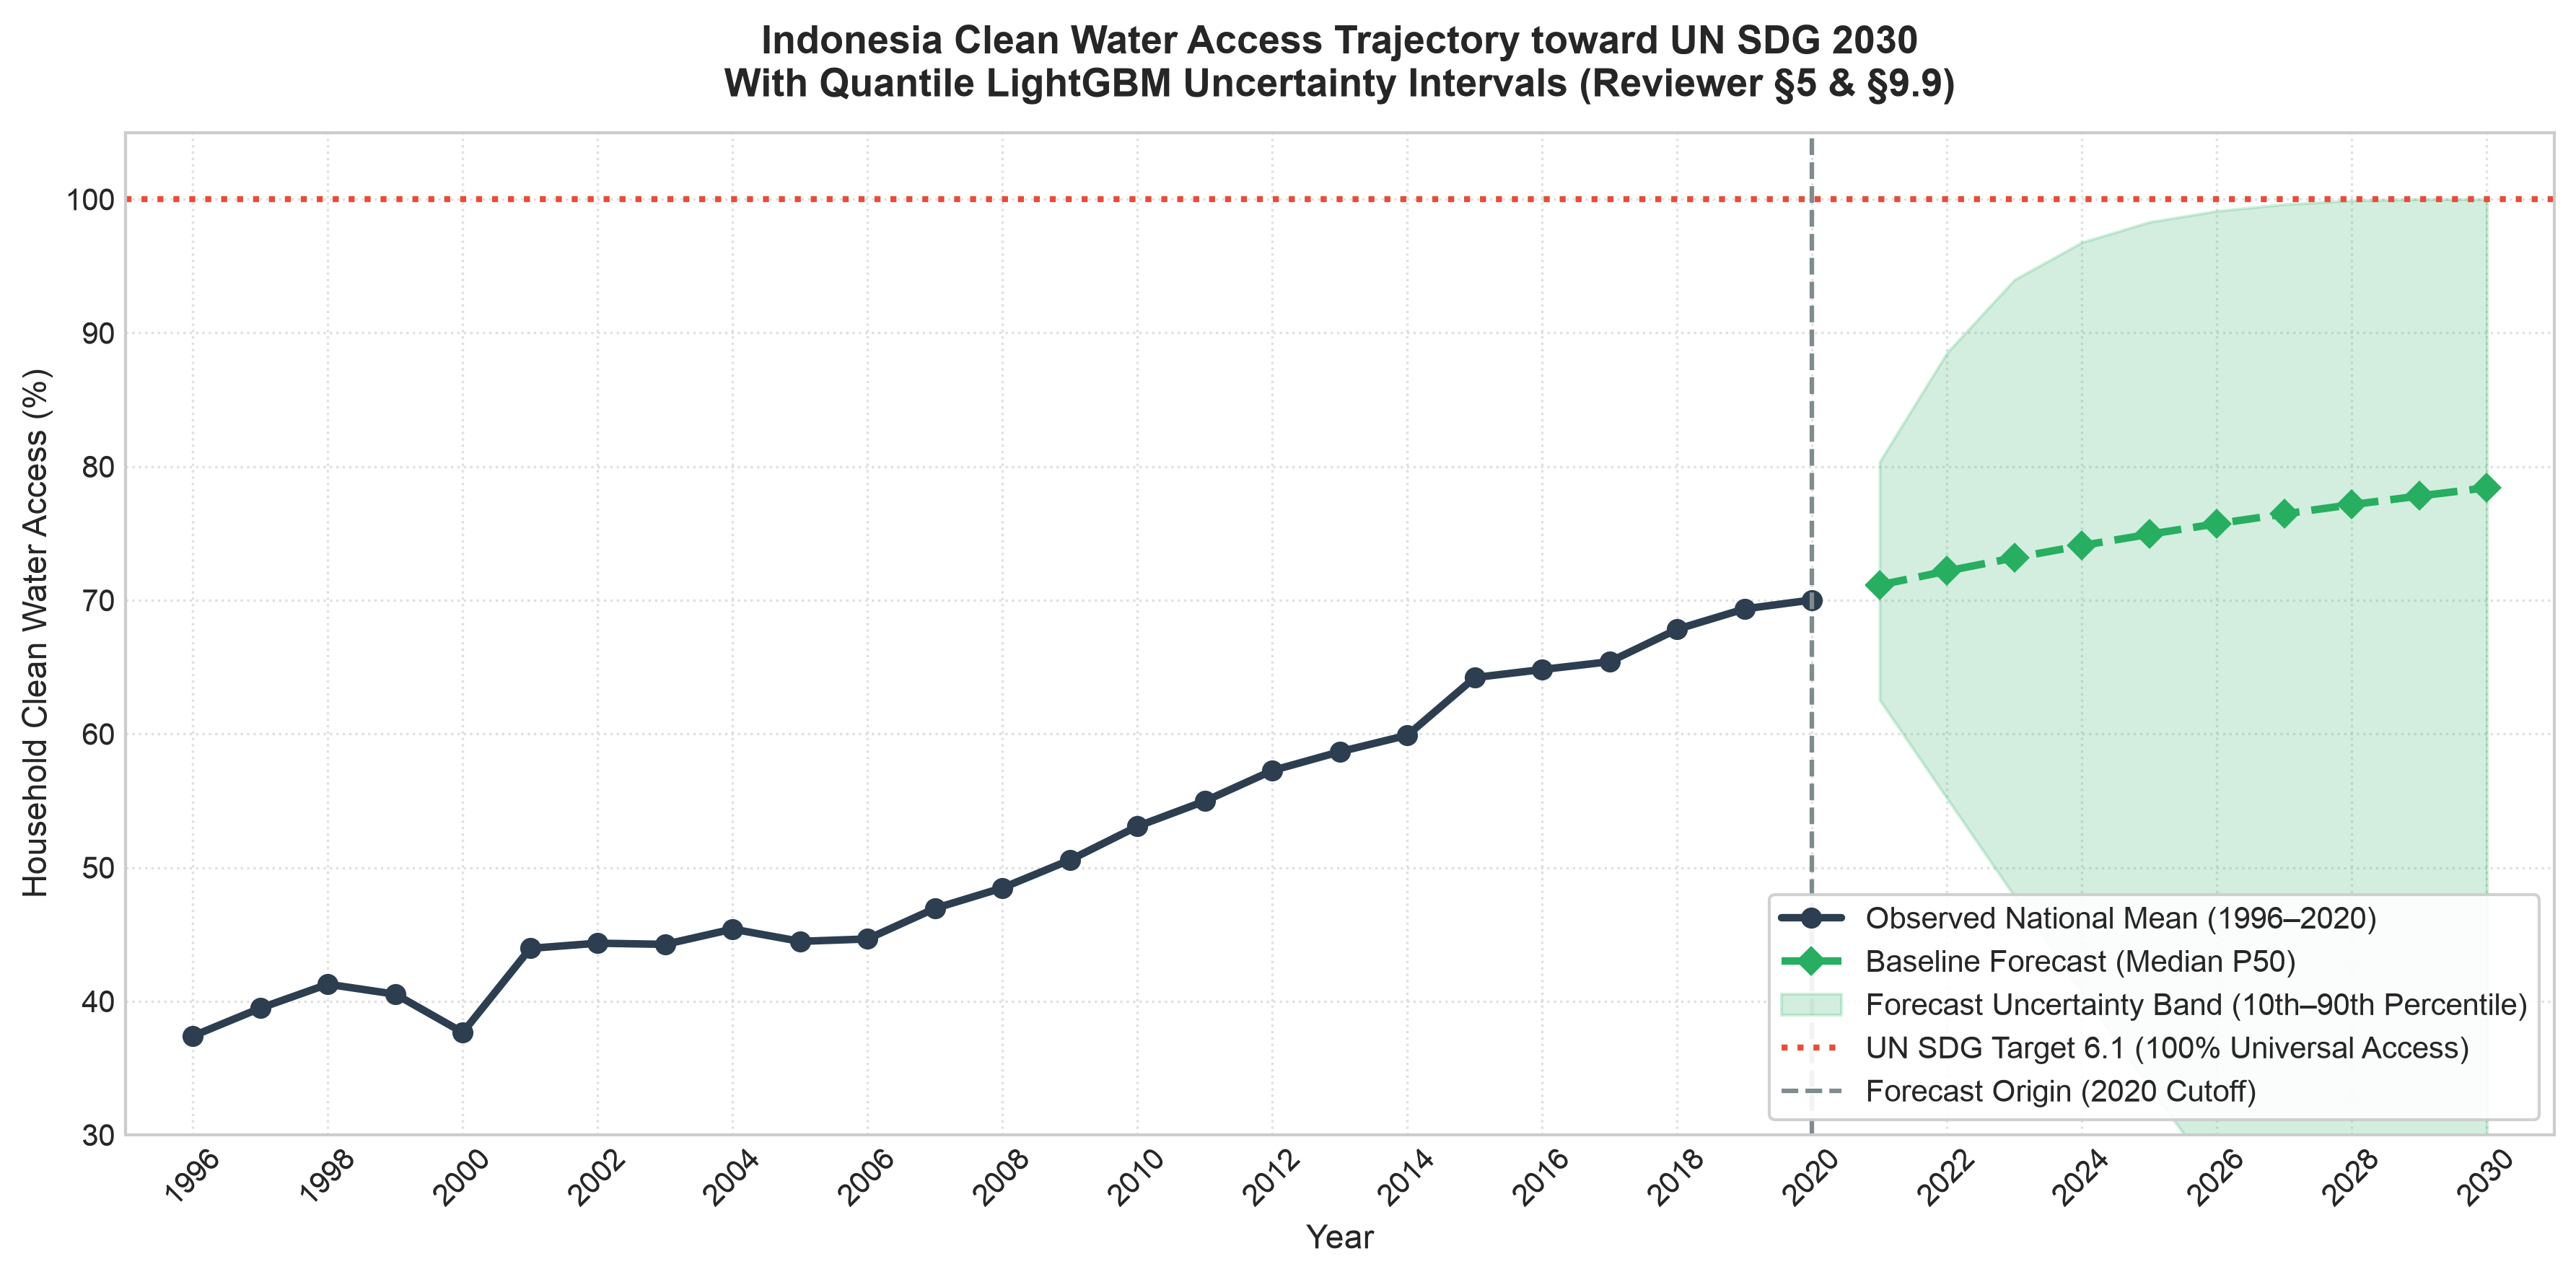

NATIONAL PROJECTION SUMMARY TOWARD SDG 2030 (%)


,water_p10,water_p50,water_p90
forecast_year,,,
2021,62.55,71.14,80.36
2022,55.17,72.19,88.53
2023,47.85,73.18,93.99
2024,40.64,74.10,96.78
2025,33.57,74.94,98.30
2026,26.71,75.73,99.12
2027,20.18,76.46,99.63
2028,14.08,77.15,99.90
2029,8.82,77.80,100.00


In [38]:
# 4. National Trajectory Visualization (Fan Chart)
nat_hist = df.groupby('year')['water'].mean()
nat_proj = df_projections.groupby('forecast_year').agg({
    'water_p10': 'mean',
    'water_p50': 'mean',
    'water_p90': 'mean'
})

plt.figure(figsize=(12, 6))
# Historical Observations
plt.plot(nat_hist.index, nat_hist.values, 'o-', color='#2c3e50', linewidth=2.5, label='Observed National Mean (1996–2020)')
# Projected Trajectory
proj_years = nat_proj.index.values
plt.plot(proj_years, nat_proj['water_p50'], 'D--', color='#27ae60', linewidth=2.5, label='Baseline Forecast (Median P50)')
plt.fill_between(proj_years, nat_proj['water_p10'], nat_proj['water_p90'], color='#27ae60', alpha=0.2, label='Forecast Uncertainty Band (10th–90th Percentile)')

# SDG 2030 Target Line
plt.axhline(y=100.0, color='#e74c3c', linestyle=':', linewidth=2, label='UN SDG Target 6.1 (100% Universal Access)')
plt.axvline(x=2020, color='#7f8c8d', linestyle='--', linewidth=1.5, label='Forecast Origin (2020 Cutoff)')

plt.title('Indonesia Clean Water Access Trajectory toward UN SDG 2030\nWith Quantile LightGBM Uncertainty Intervals (Reviewer §5 & §9.9)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Year', fontsize=11)
plt.ylabel('Household Clean Water Access (%)', fontsize=11)
plt.xlim(1995, 2031)
plt.ylim(30, 105)
plt.xticks(list(range(1996, 2031, 2)), rotation=45)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.savefig('../output/fig_projections_2030_uncertainty.png', dpi=300, bbox_inches='tight')
plt.show()

print("=" * 75)
print("NATIONAL PROJECTION SUMMARY TOWARD SDG 2030 (%)")
print("=" * 75)
display(nat_proj.round(2))
